# 08. Transformer — "어텐션이 전부다(Attention Is All You Need)"

## 🎯 이 노트북에서 배울 것
1. **셀프 어텐션**을 작은 숫자 예제로 "수작업" 계산해서 직관 잡기
2. Positional Encoding이 왜 필요한지
3. 미니 작업(정렬된 수열인지 판별)을 Transformer로 풀고, **어텐션 가중치 heatmap**으로 "무엇을 보고 판단했는지" 들여다보기

## 📖 핵심 개념
- 셀프 어텐션: `Attention(Q, K, V) = softmax(QKᵀ / √d_k) · V`
  - Q(질의), K(키), V(값): 입력 임베딩에 각각 다른 가중행렬을 곱한 것
  - `√d_k`로 나누는 이유: 차원이 커지면 QKᵀ 값이 커져 softmax가 포화 → 기울기 소실 방지
- RNN과 달리 **병렬 처리 가능**하고, 모든 토큰 쌍의 관계를 한 번에 봄 →장기 의존성 문제 해결
-응용: BERT, GPT, ViT, 번역, 이미지 생성 등 현대 AI의 기반


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록, 환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

np.random.seed(0)


## 1) 미니 예제: 3개 토큰의 셀프 어텐션을 수작업으로 계산

각 토큰이 나머지 토큰들에 "얼마나 주목하는지"가 어텐션 가중치 행렬에 그대로 드러납니다.


In [2]:
X = np.random.randn(3, 4)          # 3개 토큰의 4차원 임베딩
d = X.shape[1]
Wq = np.random.randn(d, d); Wk = np.random.randn(d, d); Wv = np.random.randn(d, d)
Q, K, V = X @ Wq, X @ Wk, X @ Wv     # 같은 입력에서 Q/K/V를 각각 다른 가중치로 생성

scores = Q @ K.T / np.sqrt(d)       # (3,3) 유사도 행렬: 토큰 i가 토큰 j에 주는 점수
# softmax (행 단위): 각 행의 합이 1이 되도록 → "확률"처럼 해석 가능
scores_stable = scores - scores.max(axis=1, keepdims=True)   # overflow 방지 (수치 안정성 트릭)
weights = np.exp(scores_stable)
weights /= weights.sum(axis=1, keepdims=True)

out = weights @ V                   # 어텐션 출력: 각 토큰이 '주목한' 토큰들의 V를 가중평균

print("어텐션 가중치 행렬 (행=질의 토큰, 열=참조 토큰):\n", np.round(weights, 3))
print("\n어텐션 출력 (3x4):\n", np.round(out, 3))
print("\n예: 첫 번째 토큰(행 0)은 토큰 0에", round(weights[0,0],2),
      ", 토큰 1에", round(weights[0,1],2), ", 토큰 2에", round(weights[0,2],2), "만큼 주목")


어텐션 가중치 행렬 (행=질의 토큰, 열=참조 토큰):
 [[0.001 0.999 0.   ]
 [0.056 0.043 0.901]
 [0.071 0.914 0.015]]

어텐션 출력 (3x4):
 [[ 0.129 -1.777 -1.397  1.535]
 [-0.63   0.054 -1.335 -0.219]
 [-0.025 -1.716 -1.579  1.479]]

예: 첫 번째 토큰(행 0)은 토큰 0에 0.0 , 토큰 1에 1.0 , 토큰 2에 0.0 만큼 주목


## 2) 미니 작업: "주어진 정수 수열이 정렬(비내림차순)되어 있는가?"

길이 10, 각 원소가 0~9인 수열을 무작위로 만들되, 절반은 정렬해서 레이블 1, 절반은 그대로 레이블 0으로 합니다.
Transformer 인코더가 이 이진 분류를 (>95% 정확도로) 수행하는지 확인합니다.


In [3]:
import torch
import torch.nn as nn

torch.manual_seed(0)
rng = np.random.default_rng(0)

def make_sample(rng, seq_len=10):
    x = rng.integers(0, 10, seq_len)
    if rng.random() < 0.5:
        return np.sort(x).astype(np.int64), 1     # 정렬된 수열 → 레이블 1
    return x.astype(np.int64), 0                   # 무작위 수열 → 레이블 0

N = 3000
seqs, labels = zip(*[make_sample(rng) for _ in range(N)])
X = torch.tensor(np.array(seqs))       # (N, 10) 정수 토큰 시퀀스
y = torch.tensor(labels)               # (N,)
Xtr, ytr = X[:2400], y[:2400]
Xte, yte = X[2400:], y[2400:]


In [4]:
class PositionalEncoding(nn.Module):
    """사인/코사인 위치 인코딩: Transformer는 순환이 없어서 '위치'를 따로 알려줘야 함"""
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()          # (max_len, 1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)    # 짝수 차원: sin
        pe[:, 1::2] = torch.cos(pos * div)    # 홀수 차원: cos
        self.register_buffer("pe", pe)        # 모델 저장 시 함께 저장되지만 학습 대상은 아님

    def forward(self, x):
        return x + self.pe[:x.size(1)]        # 토큰 임베딩 + 위치 정보

class TransformerClassifier(nn.Module):
    def __init__(self, vocab=10, d_model=32, nhead=4, num_layers=2, num_classes=2):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_model)       # 정수 토큰 → d_model 차원 벡터 (학습되는 임베딩)
        self.pos = PositionalEncoding(d_model)
        # TransformerEncoderLayer: 셀프 어텐션 + FFN(2층 MLP) + 잔차 연결 + 층 정규화가 한 블록
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                           dim_feedforward=64, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        h = self.pos(self.emb(x))       # (N, seq, d_model)
        h = self.encoder(h)             # 각 토큰이 다른 모든 토큰을보며 문맥을 만듦
        return self.fc(h.mean(dim=1))   # 시퀀스 전체를 평균 풀링해서 하나의 벡터로 요약 → 분류

model = TransformerClassifier()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for ep in range(60):
    model.train()
    opt.zero_grad()
    loss = loss_fn(model(Xtr), ytr)
    loss.backward()
    opt.step()
    if (ep + 1) % 10 == 0:
        print(f"에포크 {ep+1}: 손실 = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    acc = (model(Xte).argmax(1) == yte).float().mean().item()
print("테스트 정확도:", acc)


에포크 10: 손실 = 0.6767


에포크 20: 손실 = 0.6468


에포크 30: 손실 = 0.5657


에포크 40: 손실 = 0.3438


에포크 50: 손실 = 0.1133


에포크 60: 손실 = 0.0480
테스트 정확도: 0.9866666793823242


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51656 (\N{HANGUL SYLLABLE JIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53664 (\N{HANGUL SYLLABLE TO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53360 (\N{HANGUL SYLLABLE KEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

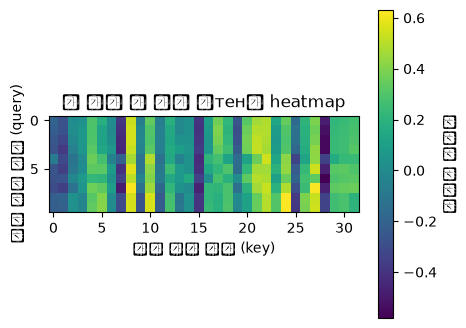

입력 수열: [0, 0, 0, 0, 2, 4, 5, 8, 9, 9] → 실제 레이블: 1 (1=정렬됨) / 예측: 1


In [5]:
# 3) 어텐션 가중치 heatmap: 모델이 '무엇을 보고' 판단했는지 시각화
model.eval()
example = Xte[:1]                     # 테스트 샘플 하나
with torch.no_grad():
    h = model.pos(model.emb(example))
    # 첫 번째 인코더 층의 셀프 어텐션 가중치를 직접 꺼냄 (평균 over heads)
    attn, _ = model.encoder.layers[0].self_attn(h, h, h, need_weights=True,
                                                 average_attn_weights=True)

plt.figure(figsize=(5, 4))
plt.imshow(attn[0].numpy(), cmap="viridis")
plt.colorbar(label="어텐션 가중치")
plt.xlabel("참조 토큰 위치 (key)"); plt.ylabel("질의 토큰 위치 (query)")
plt.title("첫 번째 층 셀프 어тен션 heatmap")
plt.show()
print("입력 수열:", example[0].tolist(), "→ 실제 레이블:", yte[0].item(),
      "(1=정렬됨) / 예측:", model(example).argmax(1).item())


## ✅ 정리

- Transformer는 **순환 없이 셀프 어텐션만으로** 시퀀스의 전역적 관계를 모델링 → 병렬화 가능,장기 의존성우수
- Q/K/V + `√d_k` 스케일링 + 위치 인코딩이 핵심 구성요소
- 인코더-디코더 구조로 번역 등 seq2seq에응용, 인코더만 쓰면 BERT(분류), 디코더만 쓰면 GPT(생성)
- 다음: [`09_AutoRegressive.ipynb`](./09_AutoRegressive.ipynb) — 자기회귀(AR) 모델과 생성의 another 축
